# The same sky map with six SkyPlot themes

This notebook uses a generated HEALPix map, so it needs no data files. Every plot uses the same map, projection, sampling, and color limits. The only changes in the first gallery come from `set_theme`. Run the cells in order.

In [8]:
import healpy as hp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

import skyplot as sp

In [2]:
npipe_143 = hp.read_map('/Users/shamik/Documents/Work/CMB_over_Berkeley/npipe6v20_143_map.fits', field=[0,1,2])
nside = hp.get_nside(npipe_143)

cmb_dipole = hp.ud_grade(hp.read_map('/Users/shamik/Documents/Work/CMB_over_Berkeley/dipole_CMB_n4096_K.fits'), nside)
cmb_quadrupole = hp.ud_grade(hp.read_map('/Users/shamik/Documents/Work/CMB_over_Berkeley/quadrupole_CMB_n4096_143GHz_K.fits'), nside)

npipe_143[0] -= (cmb_dipole + cmb_quadrupole)
npipe_143 *= 1e6  

import skytools as st
mask = st.mask_udgrade(hp.read_map('/Users/shamik/Documents/Work/so_galsci_iso/data/south_mask_nside256.fits'),nside_out=2048)

In [3]:
def show_map(title, **plot_options):
    result=sp.equidistantconic(
        npipe_143[0],
        projection_kwargs={
            "central_longitude": 15.0,
            "central_latitude": -45.0,
            "standard_parallels": (-70.0, -15.0),
        },
        extent=(-90.0, 120.0, -65.0, -5.0),  # lon_min, lon_max, lat_min, lat_max
        vmin=-300.,
        vmax=300.,
        coordinate_transform=('galactic', 'icrs'),
        # norm=sp.PlanckLogNorm(linthresh=10., vmin=-500, vmax=1e5),
        title=title,
        colorbar_title=r'$\mu$K${}_{\rm CMB}$',
        **plot_options
    )
    display(result.figure)
    plt.close(result.figure)

## Theme gallery

Academic uses `planck`, classic uses `w_ymiddle1`, and modern uses `balance`. Each dark variant keeps its theme's colormap while switching the background, text, spines, and default gridlines. Matplotlib's `rc_context` restores the previous settings after each figure.

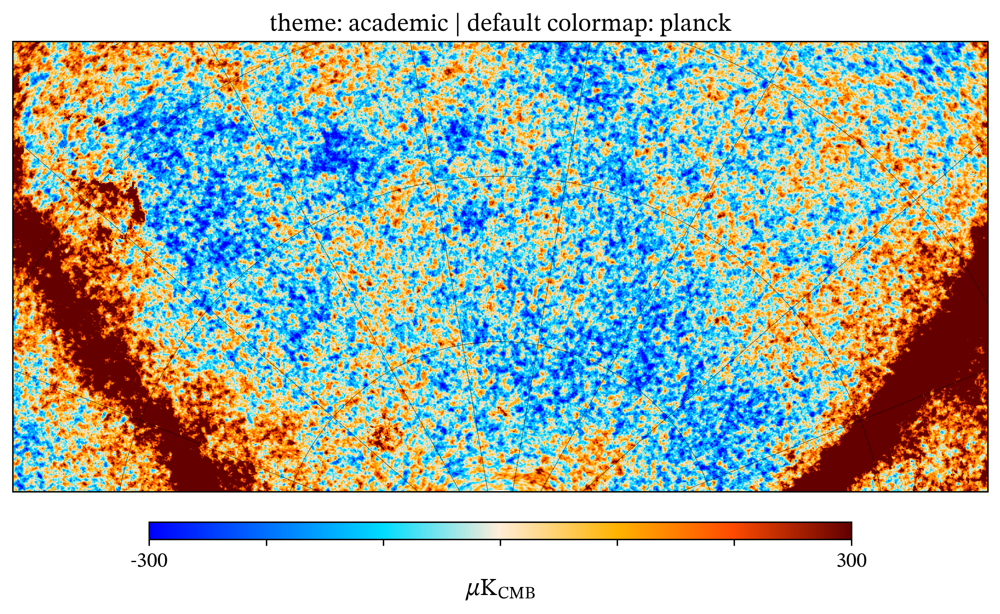

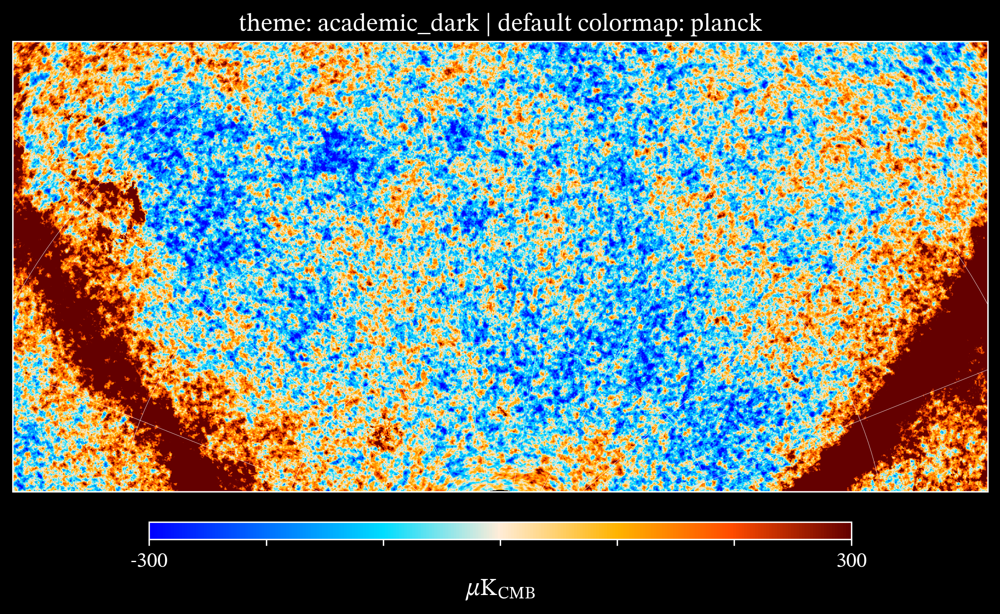

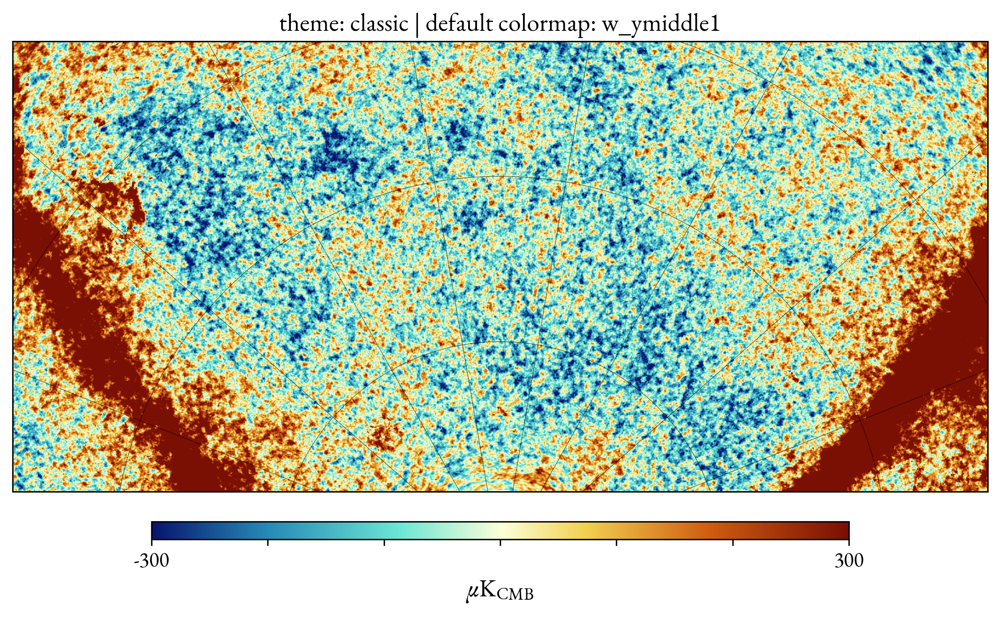

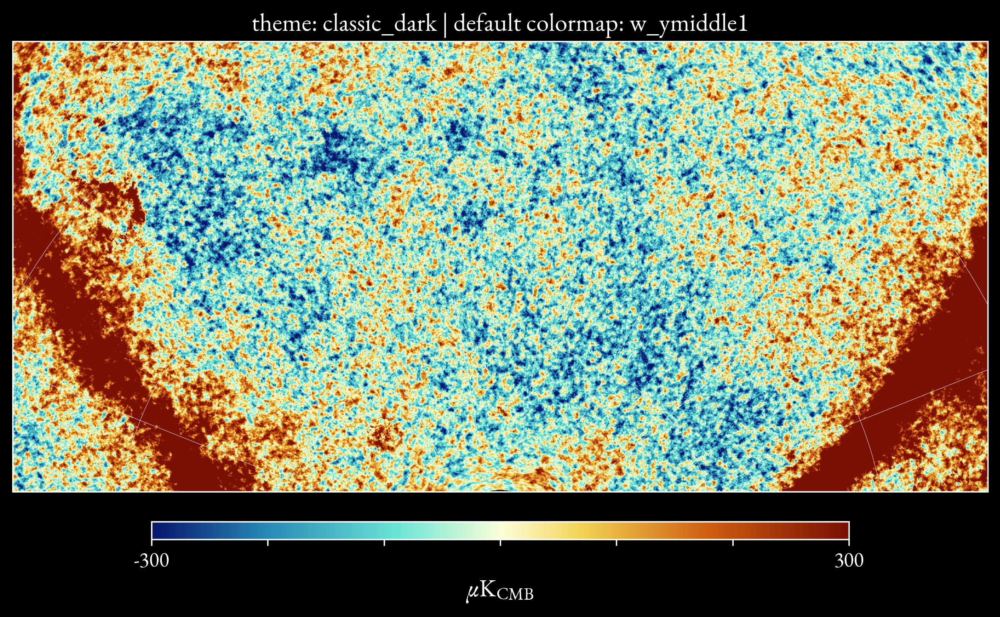

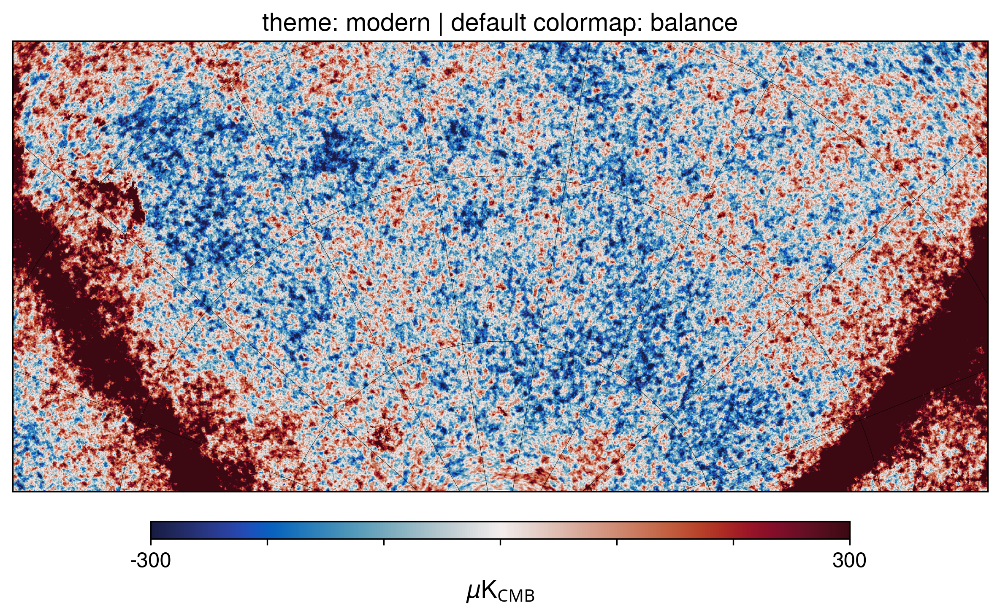

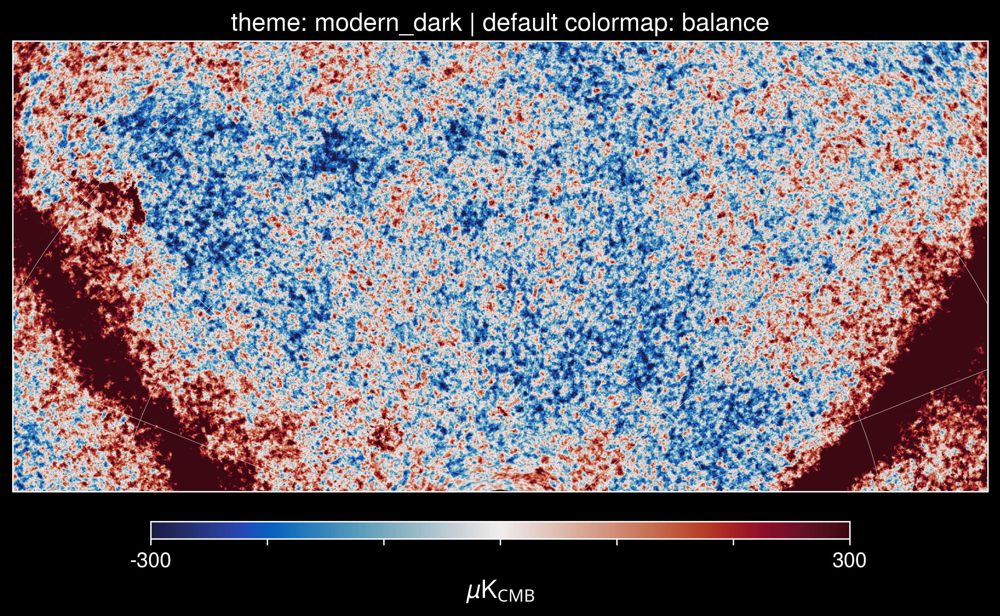

In [10]:
for theme_name in (
    "academic", "academic_dark",
    "classic", "classic_dark",
    "modern", "modern_dark",
):
    with mpl.rc_context():
        sp.set_theme(theme_name)
        show_map(f"theme: {theme_name} | default colormap: {mpl.rcParams['image.cmap']}")

## Default line color cycle

The three light themes share one 15-color line cycle, and the three dark themes share another. These patches show those colors in cycle order. Ordinary Matplotlib line plots use them when `color` is omitted; a map's colormap is a separate setting.

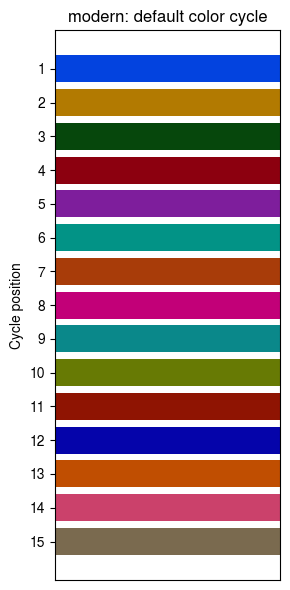

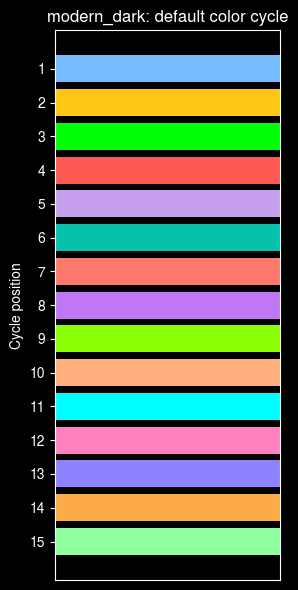

In [13]:
for theme_name in ("modern", "modern_dark"):
    with mpl.rc_context():
        sp.set_theme(theme_name)
        colors = mpl.rcParams["axes.prop_cycle"].by_key()["color"]
        fig, ax = plt.subplots(figsize=(3, 6))
        ax.barh(range(len(colors)), [1] * len(colors), color=colors, height=0.8)
        ax.set_xlim(0, 1)
        ax.set_xticks([])
        ax.set_yticks(range(len(colors)), [str(index + 1) for index in range(len(colors))])
        ax.invert_yaxis()  # Position 1 appears at the top.
        ax.set_ylabel("Cycle position")
        ax.set_title(f"{theme_name}: default color cycle")
        fig.tight_layout()
        display(fig)
        plt.close(fig)

## Override settings for one plot

Pass `cmap` and `gridline_kwargs` to a plotting function to override the theme's defaults for that plot. Here `academic_dark` still sets the fonts, background, and text colors.

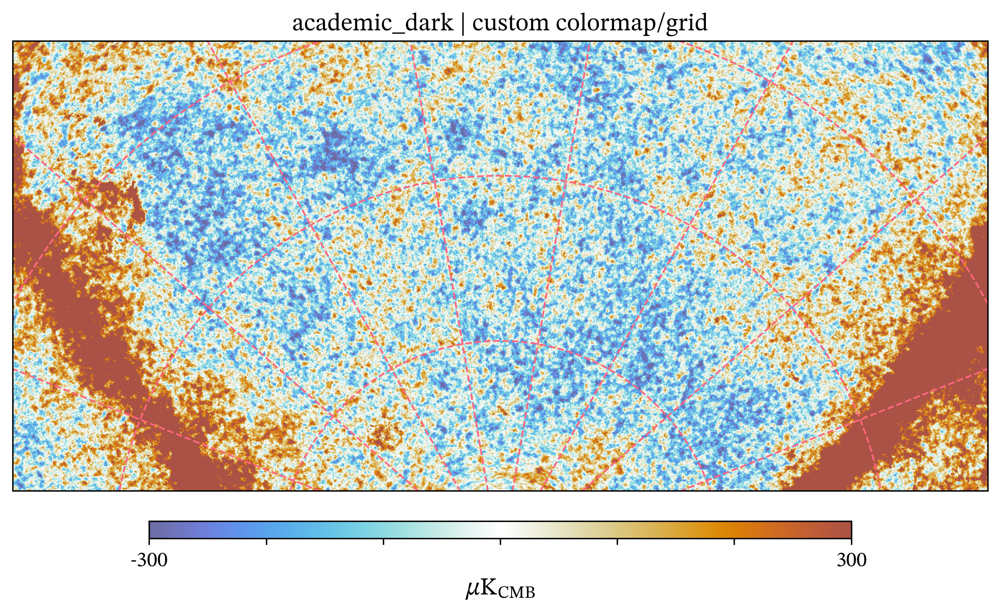

In [24]:
sp.set_theme("academic")
show_map(
    "academic_dark | custom colormap/grid",
    cmap="prinsenvlag_r",
    gridline_kwargs={"color": "#ff6680", "linewidth": 1., "linestyle": "--"},
)

## Override Matplotlib theme settings

After `set_theme`, change any Matplotlib `rcParams` you want. This example keeps the modern dark colormap but changes the title, gridlines, and figure background. The surrounding `rc_context` keeps those changes local to the example.

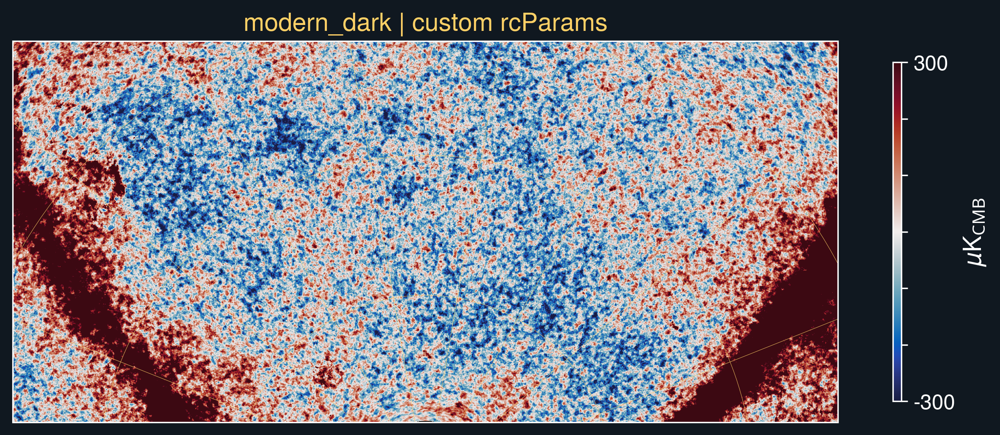

In [7]:
sp.set_theme("modern_dark")
mpl.rcParams.update({
    "axes.titlecolor": "#ffd166",
    "grid.color": "#ffd166",
    "figure.facecolor": "#101820",
    "savefig.facecolor": "#101820",
})
show_map("modern_dark | custom rcParams", colorbar_kwargs={"location":"right", "shrink": 0.6})